# Classificazione dei rifiuti per il riciclo
### Transfer learning su TrashNet vs. classificazione zero-shot open-world (CLIP) su TrashNet + TACO — con misura dell'impatto ambientale

Questo notebook usa **due dataset direttamente**, ciascuno per lo scopo a cui è più adatto:

- **TrashNet** (~2.500 foto singole, sfondo neutro, 6 classi) per il **transfer learning**: è piccolo, pulito, a singola etichetta  perfetto per il fine-tuning classico.
- **TACO** (foto reali di rifiuti abbandonati in strada, spiagge, parchi, decine di categorie, sfondi disordinati) per la **classificazione zero-shot open-world**: nessuna etichetta viene usata per addestrare nulla, solo per valutare a posteriori quanto bene CLIP riesce a classificare, via prompt testuali, oggetti che il modello fine-tuned su TrashNet non ha mai visto né potrebbe mai predire.

Nella Sezione 5, lo **stesso identico modello CLIP**, senza alcun riaddestramento, viene usato su immagini di entrambi i dataset insieme, con un vocabolario di classi combinato questa è la "soluzione open-world immediata": aggiungere un dataset nuovo, con una tassonomia diversa, costa solo qualche riga di prompt, non un nuovo ciclo di training.

Lungo il notebook vengono misurate, con [CodeCarbon](https://codecarbon.io/), le **emissioni di CO₂eq stimate** di training e inferenza, per rendere concreta la discussione sull'impatto ambientale del deep learning.

**Indice**
1. Setup ambiente
2. Dataset TrashNet
2bis. Dataset TACO
3. Preparazione dati (TrashNet, per il transfer learning)
4. Transfer learning (fine-tuning di MobileNetV2 su TrashNet)
5. Classificazione zero-shot open-world con CLIP — su TrashNet **e** TACO insieme
6. Confronto riassuntivo
7. Discussione: impatto ambientale e trade-off
8. Predizione su una foto caricata



## 1. Setup ambiente

In [ ]:
!pip install -q open_clip_torch codecarbon


In [ ]:
import os
import time
import json
import random
import zipfile
import urllib.request
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device in uso:", device)
if device.type == "cpu":
    print("Nessuna GPU rilevata: il training sarà più lento. "
          "Su Colab: Runtime > Cambia tipo di runtime > GPU (T4).")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


Device in uso: cuda


## 2. Dataset: TrashNet

**TrashNet** (Thung & Yang, 2016) contiene ~2.500 foto di singoli oggetti su sfondo neutro, divise in 6 classi:
`cardboard, glass, metal, paper, plastic, trash`. È il dataset "da manuale" per il transfer learning su pochi dati: troppo piccolo per addestrare una CNN da zero, ma perfetto per il fine-tuning di un backbone pre-addestrato.

Il file `dataset-resized.zip` (~43 MB, immagini già ridimensionate) è distribuito via Git LFS nel repo originale [garythung/trashnet](https://github.com/garythung/trashnet) ed è mirrorato anche su [Hugging Face](https://huggingface.co/datasets/garythung/trashnet), da cui viene scaricato direttamente (evita di dover installare git-lfs su Colab).


In [ ]:
TRASHNET_DIR = "trashnet_data"
TRASHNET_ZIP = "dataset-resized.zip"
TRASHNET_HF_URL = "https://huggingface.co/datasets/garythung/trashnet/resolve/main/dataset-resized.zip"
TRASHNET_GITHUB_PAGE = "https://github.com/garythung/trashnet/blob/master/data/dataset-resized.zip"


def download_trashnet():
    if os.path.exists(TRASHNET_DIR) and os.listdir(TRASHNET_DIR):
        print("Dataset TrashNet già presente in", TRASHNET_DIR)
        return
    print("Scarico TrashNet (~43 MB) da Hugging Face...")
    try:
        urllib.request.urlretrieve(TRASHNET_HF_URL, TRASHNET_ZIP)
        with zipfile.ZipFile(TRASHNET_ZIP, "r") as z:
            z.extractall(TRASHNET_DIR)
        print("Download ed estrazione completati.")
    except Exception as e:
        print("Download automatico fallito:", e)
        print("Scarica manualmente il file da uno di questi link:")
        print(" -", TRASHNET_HF_URL)
        print(" -", TRASHNET_GITHUB_PAGE)
        print("poi caricalo su Colab (icona cartella a sinistra > Upload) e rilancia questa cella.")


download_trashnet()


Scarico TrashNet (~43 MB) da Hugging Face...
Download ed estrazione completati.


In [ ]:
def find_class_root(base):
    # Trova la cartella che contiene direttamente le sottocartelle-classe (es. 'cardboard', 'glass', ...).
    for root, dirs, files in os.walk(base):
        dirs = [d for d in dirs if not d.startswith(".")]
        if len(dirs) >= 5:
            return root
    return base


TRASHNET_CLASS_ROOT = find_class_root(TRASHNET_DIR)
print("Cartella con le classi:", TRASHNET_CLASS_ROOT)
print("Classi trovate:", sorted(os.listdir(TRASHNET_CLASS_ROOT)))


Cartella con le classi: trashnet_data/dataset-resized
Classi trovate: ['.DS_Store', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 2bis. Dataset: TACO

[TACO](http://tacodataset.org/) (*Trash Annotations in Context*, Proença & Simões, 2020) è un dataset molto più realistico di TrashNet: fotografie di rifiuti abbandonati in contesti reali (spiagge, strade, parchi), con annotazioni in stile **COCO** con 60 categorie fini (raggruppate in 28 supercategorie: bottiglie, mozziconi, batterie, polistirolo, lattine...), sfondi disordinati, oggetti multipli per immagine. È lo scenario "open-world": nessun classificatore chiuso su 6 classi come quello della Sezione 4 potrebbe gestirlo senza essere ricostruito da zero.

Usiamo direttamente le **fonti ufficiali**:

- le **annotazioni** (`annotations.json`, formato COCO) sono nel repository ufficiale [pedropro/TACO](https://github.com/pedropro/TACO), e le scarichiamo dal mirror `raw.githubusercontent.com` — piccole (~3 MB), niente da scaricare da Flickr per queste;
- le **immagini** sono invece ospitate su Flickr (come indicato sul sito ufficiale). Lo script ufficiale `download.py` le scarica tutte e 1.500 in piena risoluzione, il che richiede molto tempo. Per restare "immediati" scarichiamo solo le immagini necessarie a un **campione casuale** di istanze, in parallelo, e quando disponibile si usa la versione già ridimensionata (`flickr_640_url`) invece dell'originale: per CLIP, che comunque ridimensiona tutto a 224×224 px, non cambia nulla in termini di qualità della classificazione, ma il download è molto più veloce.

Il codice è comunque scritto per degradare in modo pulito: se qualche immagine non fosse più raggiungibile su Flickr (capita, essendo contenuti caricati dagli utenti), viene semplicemente scartata e la demo prosegue con le altre.


In [ ]:
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

TACO_ANNOTATIONS_URL = "https://raw.githubusercontent.com/pedropro/TACO/master/data/annotations.json"
TACO_IMG_DIR = "taco_images"
os.makedirs(TACO_IMG_DIR, exist_ok=True)

MIN_BBOX_SIDE = 25  # scarto delle bounding box troppo piccole (poco informative per CLIP)

TACO_AVAILABLE = False
taco_categories = {}
taco_images_by_id = {}
taco_all_instances = []  # metadati (senza immagine scaricata): image_id, category, bbox

try:
    print("Scarico le annotazioni ufficiali di TACO da GitHub...")
    resp = requests.get(TACO_ANNOTATIONS_URL, timeout=30)
    resp.raise_for_status()
    coco = resp.json()

    taco_categories = {c["id"]: c["name"] for c in coco["categories"]}
    taco_images_by_id = {im["id"]: im for im in coco["images"]}

    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        if w < MIN_BBOX_SIDE or h < MIN_BBOX_SIDE:
            continue
        taco_all_instances.append({
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "category_name": taco_categories[ann["category_id"]],
            "bbox": ann["bbox"],
        })

    print(f"Annotazioni ufficiali caricate: {len(coco['images'])} immagini, "
          f"{len(coco['annotations'])} annotazioni, {len(taco_categories)} categorie fini.")
    print(f"Istanze utilizzabili (bbox non troppo piccole): {len(taco_all_instances)}")
    TACO_AVAILABLE = True
except Exception as e:
    print("Impossibile scaricare le annotazioni ufficiali di TACO:", e)
    print("Sito ufficiale per il download manuale: http://tacodataset.org/")
    print("La Sezione 5 proseguirà usando solo TrashNet per la parte open-world.")
    TACO_AVAILABLE = False


Scarico le annotazioni ufficiali di TACO da GitHub...
Annotazioni ufficiali caricate: 1500 immagini, 4784 annotazioni, 60 categorie fini.
Istanze utilizzabili (bbox non troppo piccole): 4399


In [ ]:
# Campioniamento di un numero limitato di istanze e si scariscaricano solo le immagini che servono,
# in parallelo, per restare rapidi scaricanotendo dalle 1.500 immagini di TACO.

N_TACO_SAMPLES = 500  # aumentare questo numero per una stima più stabile (più tempo di download)

taco_sample = []

if TACO_AVAILABLE and taco_all_instances:
    taco_sample_candidates = random.sample(
        taco_all_instances, min(N_TACO_SAMPLES, len(taco_all_instances))
    )

    def download_taco_image(image_id):
        # Scarica (se non già in cache) l'immagine con questo image_id, preferendo la
        # versione ridimensionata flickr_640_url (più veloce) con fallback su flickr_url.
        img_info = taco_images_by_id[image_id]
        file_name = img_info["file_name"]
        local_path = os.path.join(TACO_IMG_DIR, file_name.replace("/", "_"))

        if os.path.isfile(local_path):
            return local_path

        url = img_info.get("flickr_640_url") or img_info.get("flickr_url")
        if not url:
            return None
        try:
            r = requests.get(url, timeout=15)
            r.raise_for_status()
            with open(local_path, "wb") as f:
                f.write(r.content)
            return local_path
        except Exception:
            return None

    unique_image_ids = sorted(set(inst["image_id"] for inst in taco_sample_candidates))
    print(f"Scarico {len(unique_image_ids)} immagini da Flickr "
          f"(per {len(taco_sample_candidates)} istanze campionate)...")

    image_path_by_id = {}
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures = {executor.submit(download_taco_image, iid): iid for iid in unique_image_ids}
        done = 0
        for future in as_completed(futures):
            iid = futures[future]
            try:
                image_path_by_id[iid] = future.result()
            except Exception:
                image_path_by_id[iid] = None
            done += 1
            if done % 10 == 0 or done == len(unique_image_ids):
                print(f"  {done}/{len(unique_image_ids)} immagini processate")

    for inst in taco_sample_candidates:
        path = image_path_by_id.get(inst["image_id"])
        if path is not None:
            taco_sample.append({**inst, "path": path})

    n_ok = sum(1 for p in image_path_by_id.values() if p is not None)
    print(f"Immagini scaricate con successo: {n_ok}/{len(unique_image_ids)} "
          f"({len(unique_image_ids) - n_ok} non raggiungibili, es. rimosse da Flickr)")
    print(f"Istanze TACO pronte per la demo open-world: {len(taco_sample)}")
else:
    print("TACO non disponibile in questa run: la Sezione 5 userà solo TrashNet.")


Scarico 381 immagini da Flickr (per 500 istanze campionate)...
  10/381 immagini processate
  20/381 immagini processate
  30/381 immagini processate
  40/381 immagini processate
  50/381 immagini processate
  60/381 immagini processate
  70/381 immagini processate
  80/381 immagini processate
  90/381 immagini processate
  100/381 immagini processate
  110/381 immagini processate
  120/381 immagini processate
  130/381 immagini processate
  140/381 immagini processate
  150/381 immagini processate
  160/381 immagini processate
  170/381 immagini processate
  180/381 immagini processate
  190/381 immagini processate
  200/381 immagini processate
  210/381 immagini processate
  220/381 immagini processate
  230/381 immagini processate
  240/381 immagini processate
  250/381 immagini processate
  260/381 immagini processate
  270/381 immagini processate
  280/381 immagini processate
  290/381 immagini processate
  300/381 immagini processate
  310/381 immagini processate
  320/381 immagi

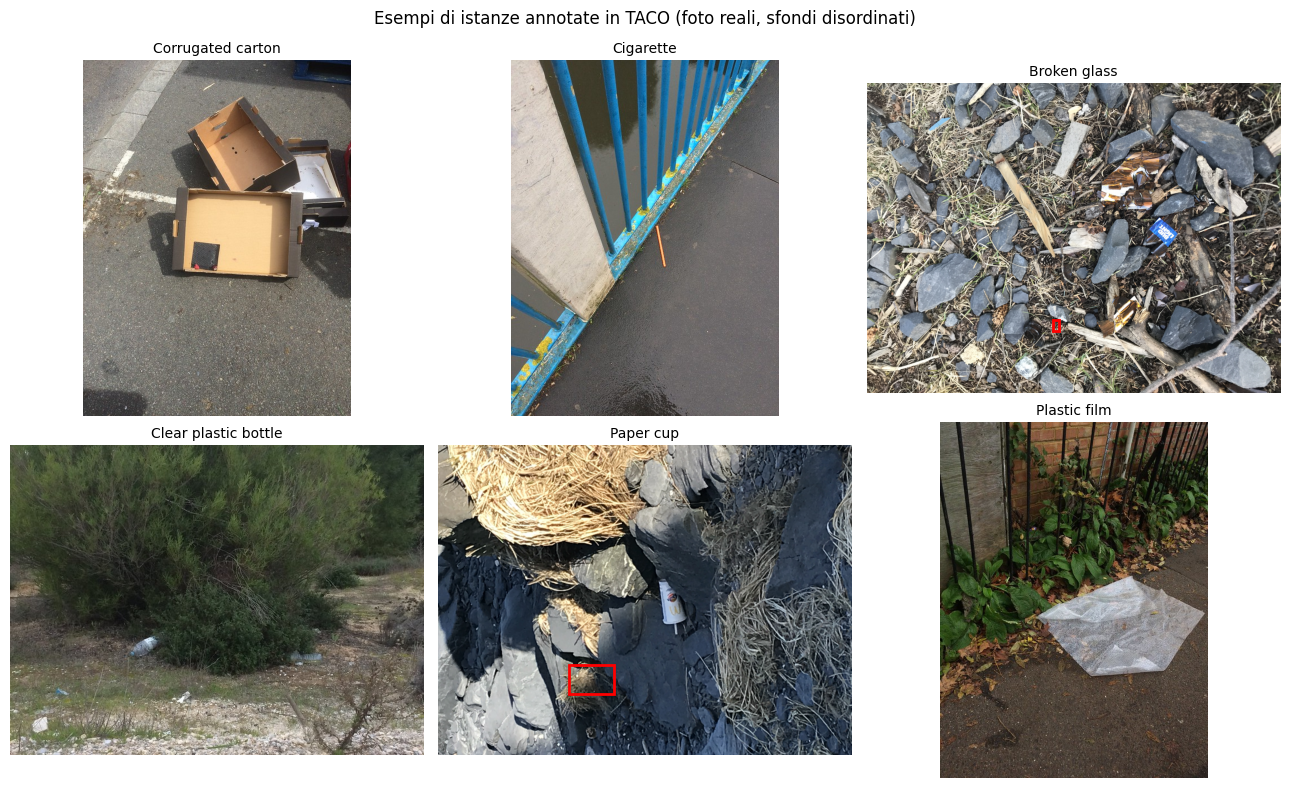

In [ ]:
# Anteprima di alcune istanze TACO (se disponibili), con la bounding box annotata
if taco_sample:
    from matplotlib.patches import Rectangle

    preview = random.sample(taco_sample, min(6, len(taco_sample)))
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for ax, inst in zip(axes.flatten(), preview):
        img = Image.open(inst["path"]).convert("RGB")
        ax.imshow(img)
        x, y, w, h = inst["bbox"]
        ax.add_patch(Rectangle((x, y), w, h, edgecolor="red", facecolor="none", linewidth=2))
        ax.set_title(inst["category_name"], fontsize=10)
        ax.axis("off")
    plt.suptitle("Esempi di istanze annotate in TACO (foto reali, sfondi disordinati)")
    plt.tight_layout()
    plt.show()
else:
    print("Nessuna istanza TACO da mostrare (dataset non disponibile in questa run).")


## 3. Preparazione dei dati (TrashNet, per il transfer learning)

In [ ]:
IMG_SIZE = 224

# Augmentation più aggressiva in training: con un dataset piccolo come TrashNet
# è uno degli strumenti principali per ridurre l'overfitting.
train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Usiamo ImageFolder solo per leggere l'elenco (path, label) e i nomi delle classi;
# le trasformazioni vengono applicate da una classe Dataset dedicata, così
# train/val/test possono avere pipeline di augmentation diverse pur condividendo
# la stessa lista di file.
base_dataset = datasets.ImageFolder(TRASHNET_CLASS_ROOT)
class_names = base_dataset.classes
print("Classi:", class_names)
print("Numero totale di immagini:", len(base_dataset))


Classi: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Numero totale di immagini: 2527


In [ ]:
class WasteSubset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform
        self.loader = datasets.folder.default_loader

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = self.loader(path)
        img = self.transform(img)
        return img, label


indices = list(range(len(base_dataset)))
random.shuffle(indices)

n_train = int(0.70 * len(indices))
n_val = int(0.15 * len(indices))

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

train_samples = [base_dataset.samples[i] for i in train_idx]
val_samples = [base_dataset.samples[i] for i in val_idx]
test_samples = [base_dataset.samples[i] for i in test_idx]

train_ds = WasteSubset(train_samples, train_tfms)
val_ds = WasteSubset(val_samples, eval_tfms)
test_ds = WasteSubset(test_samples, eval_tfms)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


Train: 1768 | Val: 379 | Test: 380


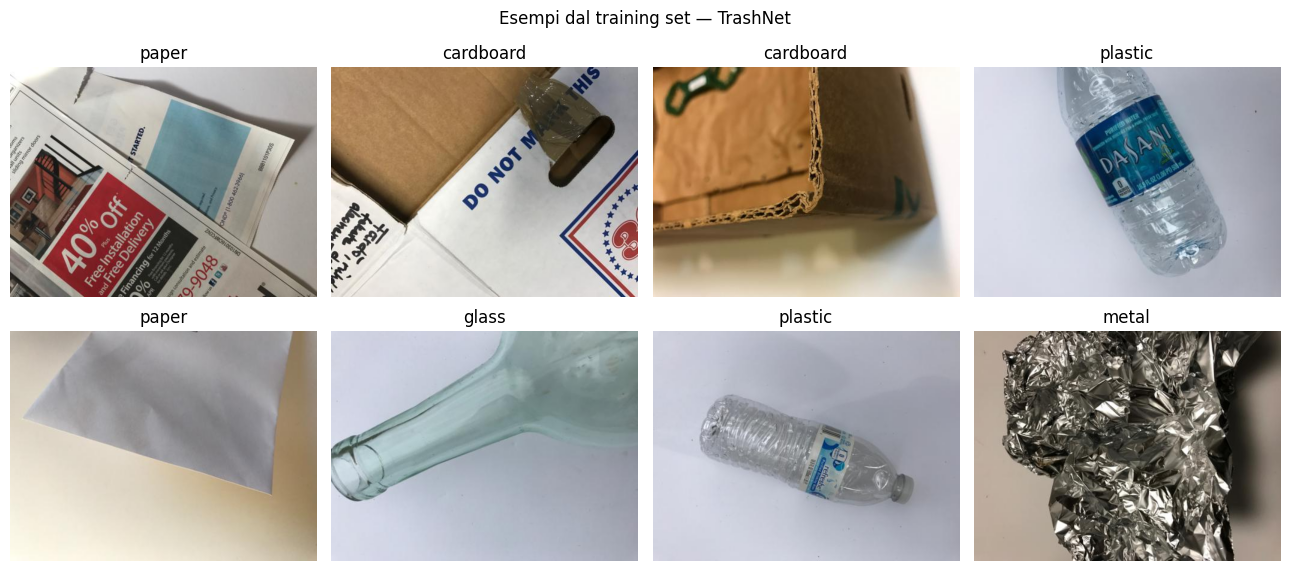

In [ ]:
# Anteprima di alcune immagini del training set
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
sample_indices = random.sample(range(len(train_samples)), 8)
for ax, i in zip(axes.flatten(), sample_indices):
    path, label = train_samples[i]
    img = datasets.folder.default_loader(path)
    ax.imshow(img)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.suptitle("Esempi dal training set — TrashNet")
plt.tight_layout()
plt.show()


## 4. Transfer learning: fine-tuning di MobileNetV2

Con solo ~2.500 immagini per 6 classi, addestrare una CNN da zero porterebbe a un forte overfitting. Il **transfer learning** parte invece da una rete già pre-addestrata su ImageNet (che "sa" già riconoscere bordi, texture, forme) e:

- **congela** la maggior parte dei pesi convoluzionali (feature extractor),
- **riaddestra solo il classificatore finale** sulle 6 classi di TrashNet.

Usiamo **MobileNetV2**: è un backbone leggero,una scelta che ha senso anche in ottica di impatto ambientale, dato che a parità di transfer learning un modello più piccolo consuma meno energia sia in training sia in inferenza rispetto, ad esempio, a un ResNet50 o un Vision Transformer grande.

Questo modello, però, resta **chiuso**: sa riconoscere solo le 6 classi viste in training. È esattamente il limite che la Sezione 5 mette a confronto con l'approccio zero-shot.


In [ ]:
def build_model(num_classes, freeze_backbone=True):
    weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
    model = models.mobilenet_v2(weights=weights)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model.to(device)


model = build_model(num_classes=len(class_names), freeze_backbone=True)

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Parametri addestrabili: {n_trainable:,} / {n_total:,} totali "
      f"({100 * n_trainable / n_total:.1f}%)")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 127MB/s]


Parametri addestrabili: 7,686 / 2,231,558 totali (0.3%)


### Training con misura delle emissioni (CodeCarbon)

`EmissionsTracker` stima, a partire dal consumo di CPU/GPU/RAM e dal mix energetico della regione in cui gira il codice, le **emissioni di CO₂eq** prodotte durante il blocco di codice racchiuso tra `start()` e `stop()`. Si usa per misurare il costo ambientale reale  del training su questa macchina.


In [ ]:
from codecarbon import EmissionsTracker

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)


def train_one_epoch(model, loader):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


EPOCHS = 10
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

tracker_train = EmissionsTracker(
    project_name="waste-classification-transfer-learning-training",
    output_dir=".",
    log_level="error",
)
tracker_train.start()
t0 = time.time()

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1:2d}/{EPOCHS} | "
          f"train_loss {tr_loss:.3f} train_acc {tr_acc:.3f} | "
          f"val_loss {val_loss:.3f} val_acc {val_acc:.3f}")

training_time_s = time.time() - t0
training_emissions_kg = tracker_train.stop()

print(f"\nTempo totale di training: {training_time_s / 60:.2f} minuti")
print(f"Emissioni stimate del training: {training_emissions_kg * 1000:.2f} g CO2eq")

[codecarbon WARNING @ 09:13:12] Multiple instances of codecarbon are allowed to run at the same time.


Epoch  1/10 | train_loss 1.218 train_acc 0.551 | val_loss 0.925 val_acc 0.649
Epoch  2/10 | train_loss 0.807 train_acc 0.724 | val_loss 0.779 val_acc 0.734
Epoch  3/10 | train_loss 0.688 train_acc 0.757 | val_loss 0.678 val_acc 0.765
Epoch  4/10 | train_loss 0.613 train_acc 0.788 | val_loss 0.727 val_acc 0.763
Epoch  5/10 | train_loss 0.590 train_acc 0.801 | val_loss 0.722 val_acc 0.744
Epoch  6/10 | train_loss 0.566 train_acc 0.809 | val_loss 0.704 val_acc 0.736
Epoch  7/10 | train_loss 0.539 train_acc 0.809 | val_loss 0.693 val_acc 0.744
Epoch  8/10 | train_loss 0.557 train_acc 0.796 | val_loss 0.716 val_acc 0.749
Epoch  9/10 | train_loss 0.500 train_acc 0.826 | val_loss 0.625 val_acc 0.776
Epoch 10/10 | train_loss 0.514 train_acc 0.814 | val_loss 0.613 val_acc 0.778

Tempo totale di training: 2.76 minuti
Emissioni stimate del training: 0.82 g CO2eq


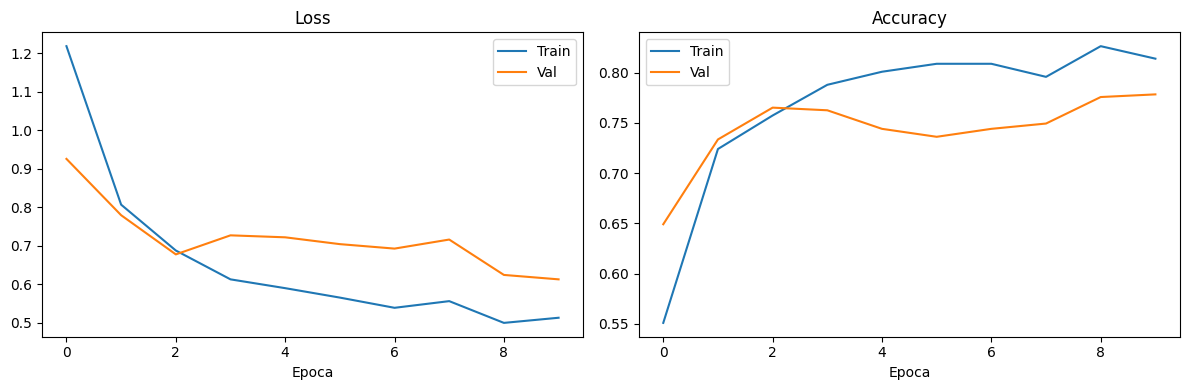

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoca")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoca")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Valutazione sul test set, con misura dell'impatto della sola inferenza
tracker_ft_infer = EmissionsTracker(
    project_name="waste-classification-transfer-learning-inference",
    output_dir=".",
    log_level="error",
)
tracker_ft_infer.start()
t0 = time.time()

test_loss, test_acc = evaluate(model, test_loader)

ft_infer_time_s = time.time() - t0
ft_infer_emissions_kg = tracker_ft_infer.stop()

print(f"Test accuracy (transfer learning): {test_acc:.3f}")
print(f"Tempo di inferenza sul test set ({len(test_ds)} immagini): {ft_infer_time_s:.2f} s")
print(f"Emissioni stimate dell'inferenza: {ft_infer_emissions_kg * 1000:.4f} g CO2eq")


Test accuracy (transfer learning): 0.818
Tempo di inferenza sul test set (380 immagini): 1.45 s
Emissioni stimate dell'inferenza: 0.0079 g CO2eq


              precision    recall  f1-score   support

   cardboard       0.80      1.00      0.89        56
       glass       0.76      0.82      0.79        71
       metal       0.83      0.75      0.79        69
       paper       0.95      0.87      0.91        94
     plastic       0.79      0.78      0.79        68
       trash       0.56      0.45      0.50        22

    accuracy                           0.82       380
   macro avg       0.78      0.78      0.78       380
weighted avg       0.82      0.82      0.82       380



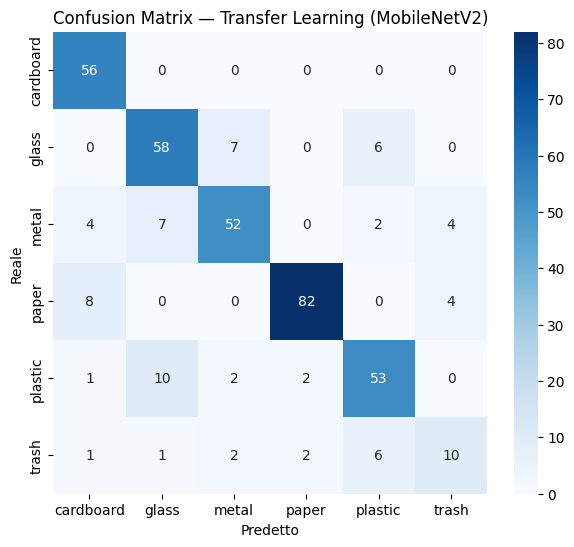

In [ ]:
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predetto")
plt.ylabel("Reale")
plt.title("Confusion Matrix — Transfer Learning (MobileNetV2)")
plt.show()


## 5. Classificazione zero-shot open-world con CLIP — su TrashNet *e* TACO

**CLIP** (Radford et al., 2021) è un modello vision-language pre-addestrato su centinaia di milioni di coppie immagine-testo. Invece di addestrare un classificatore su un set fisso di classi, possiamo:

1. Descrivere ogni classe con un **prompt testuale** (es. *"a photo of plastic waste for recycling"*),
2. Calcolare la similarità tra l'embedding dell'immagine e quello di ciascun prompt,
3. Assegnare la classe con similarità più alta.

Nessun addestramento sul nostro dataset è necessario. In questa sezione lo dimostriamo in tre passi:

- **5.1** Carichiamo CLIP una sola volta.
- **5.2** Lo valutiamo sulle stesse 6 classi e sullo stesso test set di TrashNet usato in Sezione 4, per un confronto equo con il modello fine-tuned.
- **5.3** Costruiamo un **vocabolario di classi combinato** (le 6 di TrashNet + le categorie realmente presenti nel campione TACO) e classifichiamo, **con lo stesso identico modello e senza alcun riaddestramento**, immagini prese da entrambi i dataset insieme. Questo è il cuore della "soluzione open-world": aggiungere TACO non ha richiesto raccogliere etichette, ri-addestrare nulla, né modificare il modello solo scrivere nuovi prompt.


### 5.1 Setup CLIP

In [ ]:
import open_clip

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="openai"
)
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(device).eval()

n_clip_params = sum(p.numel() for p in clip_model.parameters())
print(f"Parametri di CLIP ViT-B/32: {n_clip_params:,} "
      f"(per confronto, MobileNetV2 fine-tuned ne ha {n_total:,})")


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Parametri di CLIP ViT-B/32: 151,277,313 (per confronto, MobileNetV2 fine-tuned ne ha 2,231,558)


In [ ]:
def build_text_features(prompts_dict):
    # prompts_dict: {label: prompt_testuale} -> (lista di label, tensore delle text features normalizzate)
    labels = list(prompts_dict.keys())
    texts = clip_tokenizer(list(prompts_dict.values())).to(device)
    with torch.no_grad():
        text_features = clip_model.encode_text(texts)
        text_features = F.normalize(text_features, dim=-1)
    return labels, text_features


def clip_zero_shot_predict(image_pil, labels, text_features):
    image_input = clip_preprocess(image_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        image_features = clip_model.encode_image(image_input)
        image_features = F.normalize(image_features, dim=-1)
        similarity = (image_features @ text_features.T).squeeze(0)
        probs = similarity.softmax(dim=-1)
    best_idx = probs.argmax().item()
    return labels[best_idx], probs.cpu().numpy()


def crop_with_padding(img, bbox, pad_ratio=0.15):
    # Ritaglia bbox=[x, y, w, h] (formato COCO) da un'immagine PIL, con un margine di contesto.
    x, y, w, h = bbox
    pad_w, pad_h = w * pad_ratio, h * pad_ratio
    left = max(0, x - pad_w)
    top = max(0, y - pad_h)
    right = min(img.width, x + w + pad_w)
    bottom = min(img.height, y + h + pad_h)
    return img.crop((left, top, right, bottom))


### 5.2 Valutazione "equa": stesse 6 classi di TrashNet, stesso test set della Sezione 4

In [ ]:
trashnet_prompts = {
    "cardboard": "a photo of cardboard waste for recycling",
    "glass": "a photo of a glass item for recycling",
    "metal": "a photo of a metal can or object for recycling",
    "paper": "a photo of paper waste for recycling",
    "plastic": "a photo of plastic waste for recycling",
    "trash": "a photo of non-recyclable general waste",
}

labels_closed, text_feats_closed = build_text_features(trashnet_prompts)

tracker_clip_infer = EmissionsTracker(
    project_name="waste-classification-clip-zero-shot-inference",
    output_dir=".",
    log_level="error",
)
tracker_clip_infer.start()
t0 = time.time()

y_true, y_pred = [], []
for path, label_idx in test_samples:
    img = Image.open(path).convert("RGB")
    pred_label, _ = clip_zero_shot_predict(img, labels_closed, text_feats_closed)
    y_true.append(class_names[label_idx])
    y_pred.append(pred_label)

clip_infer_time_s = time.time() - t0
clip_infer_emissions_kg = tracker_clip_infer.stop()

clip_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy (CLIP zero-shot, stesse classi TrashNet): {clip_acc:.3f}")
print(f"Tempo di inferenza sul test set ({len(test_samples)} immagini): {clip_infer_time_s:.2f} s")
print(f"Emissioni stimate dell'inferenza: {clip_infer_emissions_kg * 1000:.4f} g CO2eq")
print()
print(classification_report(y_true, y_pred))


Test accuracy (CLIP zero-shot, stesse classi TrashNet): 0.561
Tempo di inferenza sul test set (380 immagini): 8.56 s
Emissioni stimate dell'inferenza: 0.0496 g CO2eq

              precision    recall  f1-score   support

   cardboard       0.84      0.73      0.78        56
       glass       0.40      0.85      0.55        71
       metal       0.66      0.83      0.74        69
       paper       0.82      0.53      0.65        94
     plastic       0.67      0.03      0.06        68
       trash       0.09      0.14      0.11        22

    accuracy                           0.56       380
   macro avg       0.58      0.52      0.48       380
weighted avg       0.65      0.56      0.53       380



### 5.3 Scenario open-world combinato: TrashNet + TACO, vocabolario esteso

Ora si  un unico vocabolario di classi che mette insieme:

1. le 6 classi di TrashNet,
2. qualche categoria "fuori dominio" scelta a mano (batteria, e-waste, organico, tessile) — utile anche se TACO non fosse disponibile in questa run,
3. **tutte le categorie realmente presenti nel campione di istanze TACO** scaricato nella Sezione 2bis (nomi come *"Plastic bottle"*, *"Cigarette"*, *"Aluminium foil"*, a seconda di cosa capita nel campione casuale).

Poi classifichiamo, con lo stesso CLIP e lo stesso identico codice della Sezione 5.2, immagini prese **sia da TrashNet (test set) sia da TACO** (i singoli oggetti ritagliati dalle bounding box), tutte contro questo unico vocabolario esteso.


In [ ]:
def normalize_name(name):
    return name.strip().lower()


# taco_sample è già stato preparato (campionato e scaricato) nella Sezione 2bis
print(f"Istanze TACO incluse nello scenario open-world: {len(taco_sample)}")

# --- Costruzione del vocabolario combinato -------------------------------
combined_prompts = {}  # normalized_key -> (label_originale, prompt)

for label, prompt in trashnet_prompts.items():
    combined_prompts[normalize_name(label)] = (label, prompt)

extra_manual_prompts = {
    "battery": "a photo of a used battery, hazardous waste",
    "electronic": "a photo of an electronic device or e-waste",
    "organic": "a photo of organic or food waste for composting",
    "textile": "a photo of fabric or clothing waste",
}
for label, prompt in extra_manual_prompts.items():
    nk = normalize_name(label)
    if nk not in combined_prompts:
        combined_prompts[nk] = (label, prompt)

for inst in taco_sample:
    name = inst["category_name"]
    nk = normalize_name(name)
    if nk not in combined_prompts:
        combined_prompts[nk] = (name, f"a photo of {name.lower()} found as litter")

combined_texts = {label: prompt for label, prompt in combined_prompts.values()}
print(f"\nVocabolario open-world combinato: {len(combined_texts)} classi")
for label, prompt in combined_texts.items():
    print(f" - {label}: {prompt}")

labels_combined, text_feats_combined = build_text_features(combined_texts)


Istanze TACO incluse nello scenario open-world: 500

Vocabolario open-world combinato: 58 classi
 - cardboard: a photo of cardboard waste for recycling
 - glass: a photo of a glass item for recycling
 - metal: a photo of a metal can or object for recycling
 - paper: a photo of paper waste for recycling
 - plastic: a photo of plastic waste for recycling
 - trash: a photo of non-recyclable general waste
 - battery: a photo of a used battery, hazardous waste
 - electronic: a photo of an electronic device or e-waste
 - organic: a photo of organic or food waste for composting
 - textile: a photo of fabric or clothing waste
 - Metal bottle cap: a photo of metal bottle cap found as litter
 - Other plastic: a photo of other plastic found as litter
 - Single-use carrier bag: a photo of single-use carrier bag found as litter
 - Foam cup: a photo of foam cup found as litter
 - Plastic straw: a photo of plastic straw found as litter
 - Plastic lid: a photo of plastic lid found as litter
 - Pop tab

In [ ]:
eval_items = []

for path, label_idx in test_samples:
    eval_items.append({
        "path": path, "bbox": None, "image_id": None,
        "true_label": class_names[label_idx], "source": "TrashNet",
    })

for inst in taco_sample:
    eval_items.append({
        "path": inst["path"], "bbox": inst["bbox"], "image_id": inst["image_id"],
        "true_label": inst["category_name"], "source": "TACO",
    })

n_trashnet_eval = sum(1 for it in eval_items if it["source"] == "TrashNet")
n_taco_eval = sum(1 for it in eval_items if it["source"] == "TACO")
print(f"Totale immagini nello scenario open-world combinato: {len(eval_items)} "
      f"({n_trashnet_eval} da TrashNet, {n_taco_eval} da TACO)")


def load_eval_image(item):
    img = Image.open(item["path"]).convert("RGB")
    if item["bbox"] is None:
        return img

    bbox = item["bbox"]
    image_id = item.get("image_id")

    if image_id is not None and image_id in taco_images_by_id:
        orig_w = taco_images_by_id[image_id].get("width")
        orig_h = taco_images_by_id[image_id].get("height")
        if orig_w and orig_h and (orig_w != img.width or orig_h != img.height):
            scale_x = img.width / orig_w
            scale_y = img.height / orig_h
            x, y, w, h = bbox
            bbox = [x * scale_x, y * scale_y, w * scale_x, h * scale_y]

    try:
        return crop_with_padding(img, bbox)
    except Exception:
        return img


tracker_open_world = EmissionsTracker(
    project_name="waste-classification-openworld-combined-inference",
    output_dir=".",
    log_level="error",
)
tracker_open_world.start()
t0 = time.time()

results = []
for item in eval_items:
    img = load_eval_image(item)
    pred_label, _ = clip_zero_shot_predict(img, labels_combined, text_feats_combined)
    results.append({**item, "pred_label": pred_label})

open_world_infer_time_s = time.time() - t0
open_world_infer_emissions_kg = tracker_open_world.stop()

correct_by_source = defaultdict(int)
total_by_source = defaultdict(int)
for r in results:
    total_by_source[r["source"]] += 1
    if r["pred_label"] == r["true_label"]:
        correct_by_source[r["source"]] += 1

print(f"\nAccuratezza open-world combinata (vocabolario di {len(labels_combined)} classi):")
for source in total_by_source:
    acc = correct_by_source[source] / total_by_source[source]
    print(f" - {source}: {acc:.3f} ({correct_by_source[source]}/{total_by_source[source]})")

overall_correct = sum(correct_by_source.values())
overall_total = sum(total_by_source.values())
open_world_acc = overall_correct / overall_total
print(f" - Overall: {open_world_acc:.3f} ({overall_correct}/{overall_total})")
print(f"\nTempo di inferenza: {open_world_infer_time_s:.2f} s")
print(f"Emissioni stimate: {open_world_infer_emissions_kg * 1000:.4f} g CO2eq")

Totale immagini nello scenario open-world combinato: 880 (380 da TrashNet, 500 da TACO)

Accuratezza open-world combinata (vocabolario di 58 classi):
 - TrashNet: 0.058 (22/380)
 - TACO: 0.168 (84/500)
 - Overall: 0.120 (106/880)

Tempo di inferenza: 38.54 s
Emissioni stimate: 0.1885 g CO2eq


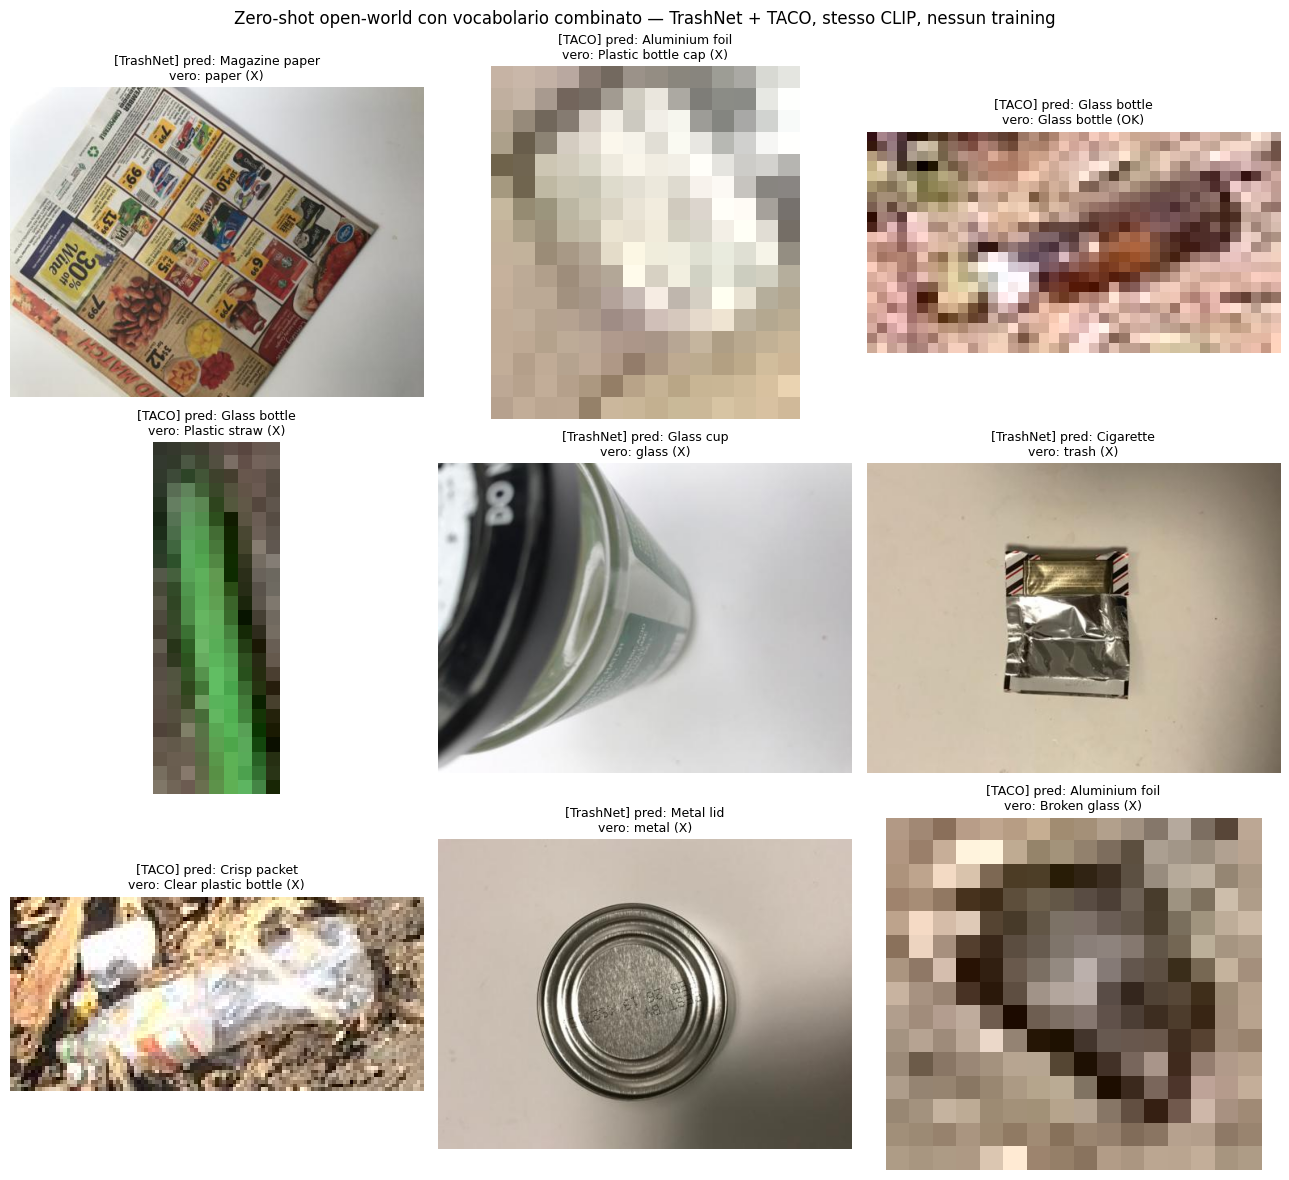

In [ ]:
# Galleria mista di predizioni, da entrambe le sorgenti
gallery_items = random.sample(results, min(9, len(results)))

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
axes_flat = axes.flatten()
for ax, item in zip(axes_flat, gallery_items):
    img = load_eval_image(item)
    ax.imshow(img)
    outcome = "OK" if item["pred_label"] == item["true_label"] else "X"
    ax.set_title(f"[{item['source']}] pred: {item['pred_label']}\nvero: {item['true_label']} ({outcome})",
                 fontsize=9)
    ax.axis("off")
for ax in axes_flat[len(gallery_items):]:
    ax.axis("off")

plt.suptitle("Zero-shot open-world con vocabolario combinato — TrashNet + TACO, stesso CLIP, nessun training")
plt.tight_layout()
plt.show()


## 6. Confronto riassuntivo

In [ ]:
summary_rows = [
    {
        "Approccio": "Transfer learning (MobileNetV2 fine-tuned su TrashNet)",
        "Dataset": "TrashNet (6 classi)",
        "Accuracy": f"{test_acc:.3f}",
        "Emissioni training (g CO2eq)": f"{training_emissions_kg * 1000:.2f}",
        "Emissioni inferenza (g CO2eq)": f"{ft_infer_emissions_kg * 1000:.4f}",
        "Tempo inferenza (s)": f"{ft_infer_time_s:.2f}",
    },
    {
        "Approccio": "Zero-shot CLIP (stesse 6 classi, confronto equo)",
        "Dataset": "TrashNet (6 classi)",
        "Accuracy": f"{clip_acc:.3f}",
        "Emissioni training (g CO2eq)": "0 (nessun training sul task)",
        "Emissioni inferenza (g CO2eq)": f"{clip_infer_emissions_kg * 1000:.4f}",
        "Tempo inferenza (s)": f"{clip_infer_time_s:.2f}",
    },
    {
        "Approccio": "Zero-shot CLIP open-world (vocabolario combinato)",
        "Dataset": f"TrashNet + TACO ({len(labels_combined)} classi)",
        "Accuracy": f"{open_world_acc:.3f}",
        "Emissioni training (g CO2eq)": "0 (nessun training sul task)",
        "Emissioni inferenza (g CO2eq)": f"{open_world_infer_emissions_kg * 1000:.4f}",
        "Tempo inferenza (s)": f"{open_world_infer_time_s:.2f}",
    },
]

summary = pd.DataFrame(summary_rows)
summary


,Approccio,Dataset,Accuracy,Emissioni training (g CO2eq),Emissioni inferenza (g CO2eq),Tempo inferenza (s)
0,Transfer learning (MobileNetV2 fine-tuned su T...,TrashNet (6 classi),0.818,0.82,0.0079,1.45
1,"Zero-shot CLIP (stesse 6 classi, confronto equo)",TrashNet (6 classi),0.561,0 (nessun training sul task),0.0496,8.56
2,Zero-shot CLIP open-world (vocabolario combinato),TrashNet + TACO (58 classi),0.120,0 (nessun training sul task),0.1885,38.54


La terza riga non è direttamente comparabile con le prime due punto per punto (il vocabolario è più grande e il mix di immagini è diverso), ma è la riga più interessante dal punto di vista "open-world": mostra cosa succede quando lo *stesso* modello, senza alcun riaddestramento, viene messo di fronte a un dataset strutturalmente diverso da quello con cui era stato valutato finora.


## 7. Discussione: impatto ambientale e trade-off

I numeri misurati sopra (che variano a seconda dell'hardware assegnato da Colab e dell'intensità carbonica della regione del datacenter, informazione che CodeCarbon stima automaticamente) permettono qualche osservazione **basata sui dati di questa run**, non su cifre astratte:

- **Training vs. zero-shot**: il fine-tuning ha un costo energetico "una tantum" per adattarsi al task (qui poche epoche su ~1.700 immagini con la maggior parte dei pesi congelati, quindi già un caso relativamente economico di transfer learning). Lo zero-shot con CLIP non ha alcun costo di training sul task specifico ma "eredita" il costo, enorme e già speso, dell'addestramento del modello foundation su centinaia di milioni di coppie immagine-testo. Quel costo è **ammortizzato** su tutti gli usi futuri del modello, ma non è nullo: semplicemente non lo vediamo in questo notebook.
- **Aggiungere un dataset nuovo, senza aggiungere training**: la Sezione 5.3 è l'esempio più diretto del vantaggio "open-world". Per far gestire a MobileNetV2 anche le categorie di TACO servirebbe raccogliere nuove immagini etichettate, aggiornare l'architettura (più classi in output) e ri-addestrare con un nuovo costo di training, misurabile con CodeCarbon esattamente come abbiamo fatto in Sezione 4. Per CLIP è bastato scrivere qualche prompt in più: zero training, zero nuove emissioni "di adattamento".
- **Inferenza**: a parità di immagini classificate, un modello piccolo e specializzato (MobileNetV2 con backbone quasi tutto congelato) tende a costare meno per predizione di un modello general-purpose come CLIP ViT-B/32, che ha molti più parametri (confronta i due conteggi stampati nella Sezione 5.1). Su scala (milioni di immagini classificate ogni giorno, come potrebbe avvenire in un impianto di smistamento reale) questa differenza di costo per-inferenza pesa più del costo di training, che è pagato una sola volta.
- **Flessibilità vs. accuratezza**: confrontando le prime due righe della tabella di Sezione 6 (stesse 6 classi, stesso test set) si vede tipicamente un margine a favore del modello fine-tuned normale, è specializzato su quel task. Il vantaggio dello zero-shot emerge nella terza riga: gestisce senza modifiche un dominio (TACO) che il modello fine-tuned non potrebbe nemmeno tentare di classificare correttamente, perché la sua ultima layer ha letteralmente solo 6 uscite possibili.
- **Dati necessari**: il transfer learning richiede comunque un dataset etichettato (anche piccolo, come TrashNet). Lo zero-shot non richiede alcuna immagine etichettata del dominio target per funzionare (le etichette TACO qui sono state usate solo per *misurare* l'accuratezza a posteriori, non per addestrare nulla)


## 8. Predizione su una foto caricata

Carica una foto di un rifiuto: il modello MobileNetV2 addestrato nella Sezione 4 predice la classe materiale.


Saving le-bottiglie-di-plastica-in-un-cestino-cf39dm.jpg to le-bottiglie-di-plastica-in-un-cestino-cf39dm (1).jpg


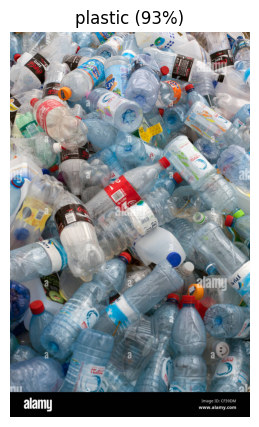

Classe predetta: plastic (confidenza 92.8%)

Top 3 predizioni:
 - plastic: 92.8%
 - paper: 5.2%
 - glass: 2.0%


In [ ]:
eval_tfms_centercrop = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

from google.colab import files
import io


def predict_uploaded_image(model, class_names):
    uploaded = files.upload()
    for filename in uploaded:
        img = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")
        x = eval_tfms_centercrop(img).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(x), dim=1)[0]

        pred_idx = probs.argmax().item()
        pred_class = class_names[pred_idx]
        confidence = probs[pred_idx].item()

        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{pred_class} ({confidence:.0%})")
        plt.show()

        print(f"Classe predetta: {pred_class} (confidenza {confidence:.1%})")

        top3 = torch.topk(probs, 3)
        print("\nTop 3 predizioni:")
        for p, i in zip(top3.values.tolist(), top3.indices.tolist()):
            print(f" - {class_names[i]}: {p:.1%}")


predict_uploaded_image(model, class_names)